# Cymbal Audio Analysis

We're going to examine a raw wav audio file containing individual cymbal strikes at 20 a piece in three different locations, for a total of 60 separate strikes. The objective is to investigate how the location at which a cymbal is struck affects the frequency characteristics of the resulting sound. We'll be using Numpy to handle our array and numerical operations, SciPy to read in the WAV file, for its Fast Fourier Transform tools, and other helpful wave tools, and Matplotlib to plot our results and gain a visual understanding of our findings. 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import find_peaks

## Loading the Raw Audio Data

We're importing the raw WAV file into Python using SciPy. The recording was sampled at 48,000 samples per second and contains a single audio channel. 

In [3]:
sample_rate, audio = wavfile.read('cymbal_analysis_raw.wav')

In [4]:
print('Sample rate:', sample_rate)
print('Audio shape:', audio.shape)
print('Data type:', audio.dtype)

Sample rate: 48000
Audio shape: (38461440,)
Data type: int16


## Plotting the Whole Audio File

Plotting the entire WAV file here. Just want to get a feel for what we're working with before splitting this up.

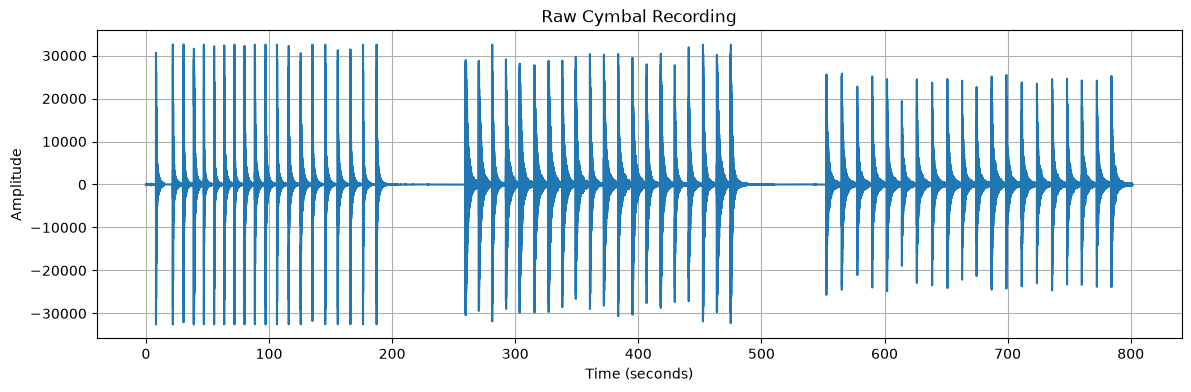

In [5]:
time = np.arange(len(audio))/sample_rate

plt.figure(figsize=(14, 4))
plt.plot(time, audio)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Raw Cymbal Recording')
plt.grid(True)
plt.show()

## Separating the Recording into Experimental Groups

As shown above, the full recording contains three sections corresponding to three strike locations. Separate plots will now be used to examine the timing and consistency of the recorded strikes within each group.

The time ranges used initially are approximate and will be refined by inspecting the plots. To make the individual strikes more easily distinguished, the signal is summarized using RMS amplitude in short time windows. The purpose here is to reduce the amount of data displayed without modifying the original recording.

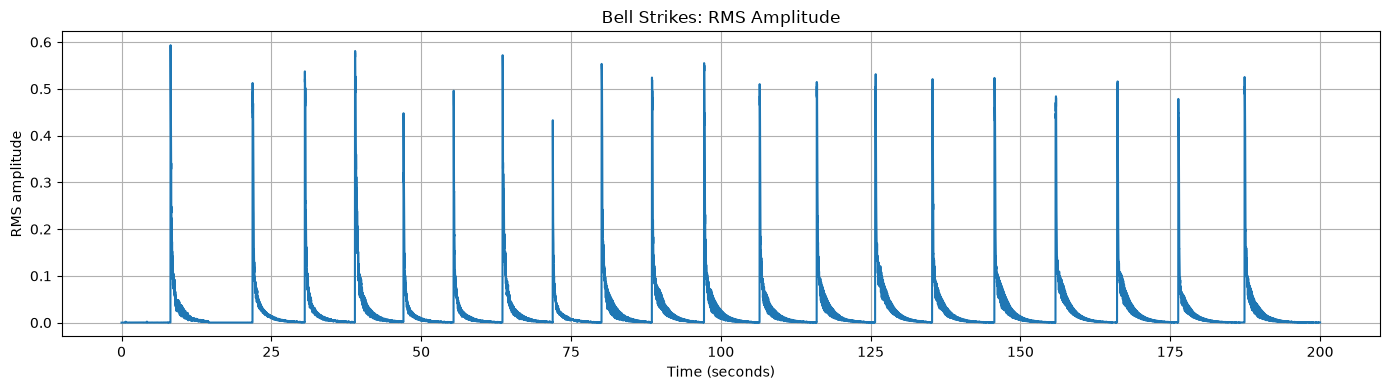

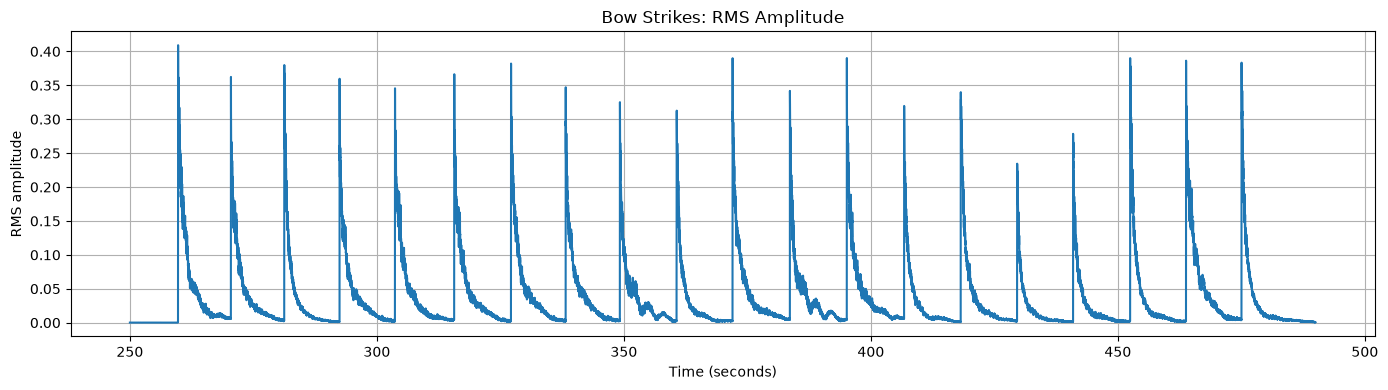

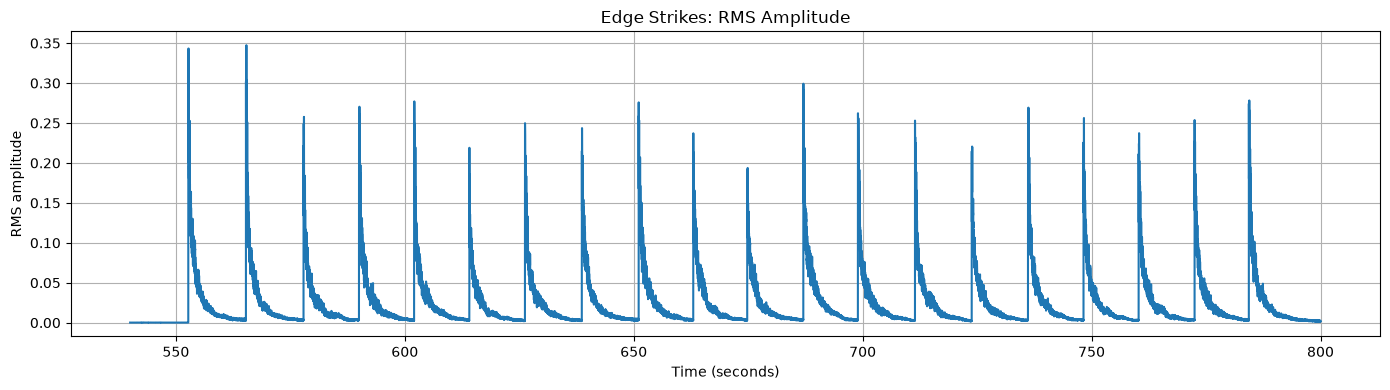

In [6]:
# I need to convert the integer audio samples to floating point values that are within the range of -1 to 1.
# The type shown in cell 3 of int16 indicates a range of -32,768 to 32,767, so we need to divide by the upper value.
audio_float = audio.astype(np.float64) / 32768.0

# Using approximate ranges here based on the graph above. 
groups = {'Bell': (0, 200), 'Bow': (250, 490), 'Edge': (540, 800)}

# Now to calculate the Root Mean Square (RMS) amplitude. Using a 10 millisecond window seems reasonable for
# us to gather groupings of 48,000 * 0.01 = 480 samples to work with.
window_size = int(0.01*sample_rate)

# Storing each envelope to determine exact onset time as needed for the next step.
rms_envelopes = {}

for name, (start_time, end_time) in groups.items():
    start_index = int(start_time*sample_rate)
    end_index = int(end_time*sample_rate)
    segment = audio_float[start_index:end_index]

    # Now let's divide these into equal sized windows.
    usable_length = (len(segment)//window_size)*window_size
    windows = segment[:usable_length].reshape(-1, window_size)

    # RMS will measure the signal's strength within each window.
    rms = np.sqrt(np.mean(windows**2, axis=1))

    # Use the center of each window for its time coordinate.
    times = (start_time + (np.arange(len(rms)) + 0.5)*window_size/sample_rate)

    rms_envelopes[name] = {'times': times, 'rms': rms}

    # Finally, to plot the RMS for this grouping.
    plt.figure(figsize=(14, 4))
    plt.plot(times, rms)
    plt.xlabel('Time (seconds)')
    plt.ylabel('RMS amplitude')
    plt.title(f'{name} Strikes: RMS Amplitude')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Quick Stop Analysis

The three graphs above appear consistent with expectations. The bell strikes look to decay quickly, the bow less so, and the edge hits decay the least quickly.

## Identifying Individual Cymbal Strikes

Before we perform the Fourier analysis, each cymbal strike must be identified and isolated from the continuous recording. We'll need to determine the exact onset time and duration of each strike. We'll be using the assistance of SciPy's find_peaks function here.

The RMS amplitude envelopes provide a useful overview of the recording, however, the onset times should be determined more precisely before extracting individual audio segements. Once the individual strikes have been identified, their timing information can be used to extract the corresponding samples from the original audio recording. The extracted segments will then serve as the input for the Fast Fourier Transform (FFT), which will be used to examine the frequency characteristics of each strike.

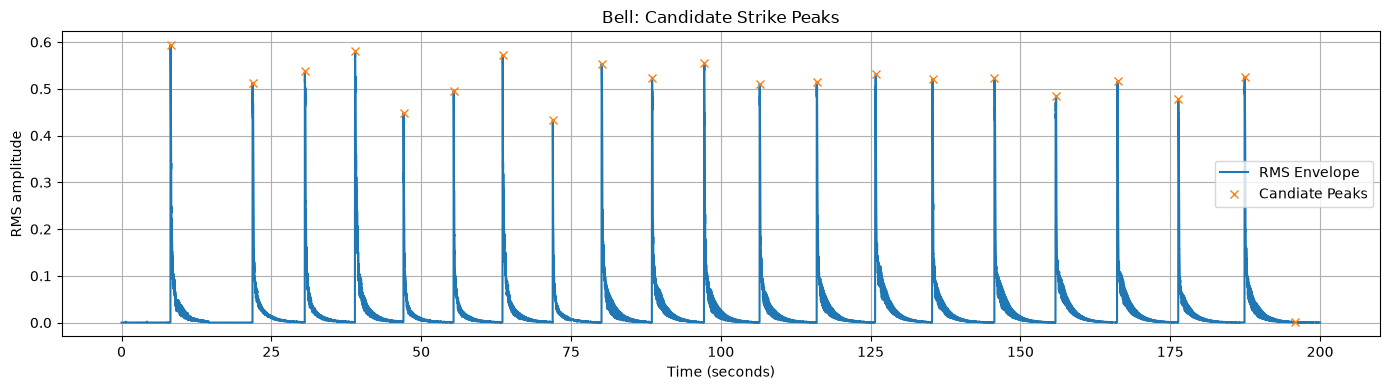

Bell: 21 candidate peaks
Candidate times (seconds):
[  8.18  21.88  30.6   38.98  47.06  55.42  63.6   71.96  80.11  88.52
  97.22 106.48 116.02 125.84 135.34 145.66 155.93 166.22 176.34 187.4
 195.74]



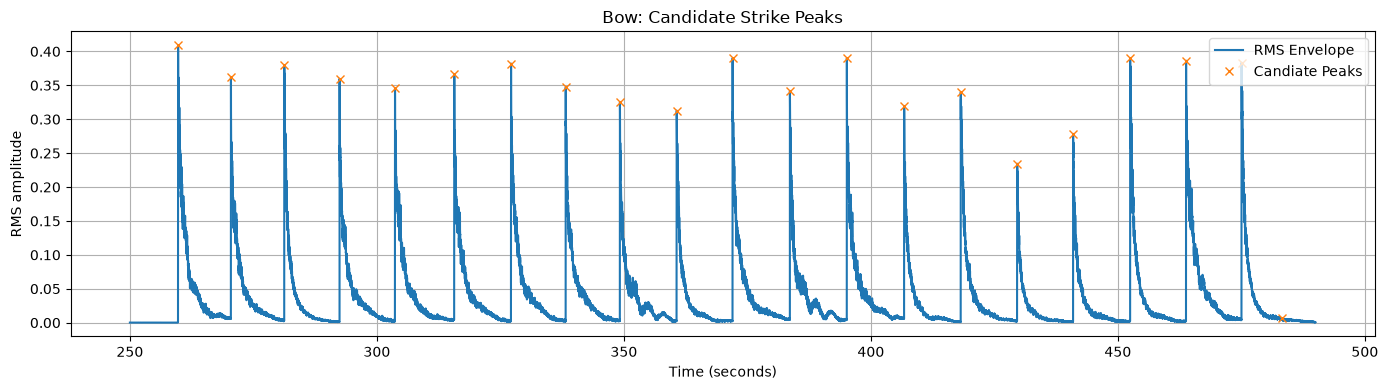

Bow: 21 candidate peaks
Candidate times (seconds):
[259.76 270.46 281.26 292.46 303.68 315.68 327.17 338.24 349.2  360.7
 372.02 383.62 395.14 406.74 418.21 429.62 440.94 452.5  463.82 475.04
 483.18]



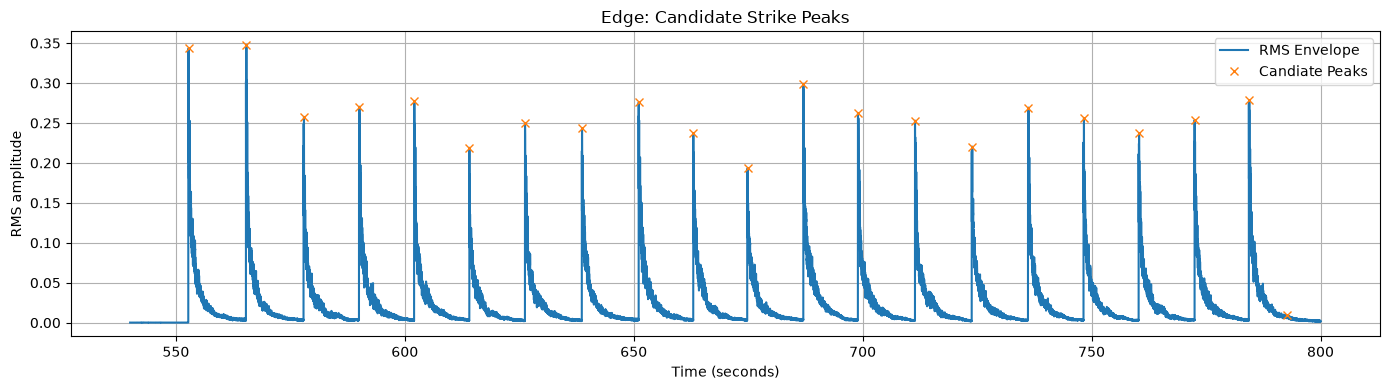

Edge: 21 candidate peaks
Candidate times (seconds):
[552.76 565.4  577.98 590.08 602.08 614.1  626.26 638.71 651.08 663.02
 674.88 687.06 698.98 711.44 723.9  736.2  748.34 760.38 772.5  784.44
 792.58]



In [7]:
# Finding the individual strike onsets.
min_separation = 8.0

verified_peak_times = {}

# Using the rms evelope items created in cell 8.
for name, data in rms_envelopes.items():
    times = data['times']
    rms = data['rms']

    # We need a min distance passed in to the find_peaks function or we get flooded with potential candidates.
    min_distance = int(min_separation/0.01)

    peaks, properties = find_peaks(rms, distance=min_distance, prominence=0.0005)

    candidate_times = times[peaks]

    # Graphs below will show that the last value can be discarded for purposes of finding the actual peaks.
    # See md cell Selected Strike Event Verification below for further clarification as needed.
    verified_peak_times[name] = candidate_times[:20]

    plt.figure(figsize=(14, 4))
    plt.plot(times, rms, label='RMS Envelope')
    plt.plot(times[peaks], rms[peaks], 'x', label='Candiate Peaks')

    plt.xlabel('Time (seconds)')
    plt.ylabel('RMS amplitude')
    plt.title(f'{name}: Candidate Strike Peaks')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f'{name}: {len(peaks)} candidate peaks')
    print('Candidate times (seconds):')
    print(np.round(times[peaks], 2))
    print()

## Detected Strike Event Verification

The detector identified 21 candidate peaks in each experimental group, although the experiment consisted of 20 strikes per location. Visual inspection of the RMS plots showed that the final candidate in each group occurred during the decay of the final strike rather than representing a separate strike. Based on this inspection and the known experimental design, the final candidate was excluded from each group's list of detected events that are now properly stored in verified_peak_times.

The peak times are used to identify individual strikes, but they do not necessarily represent the exact onset times. The onset of each strike will be estimated separately before extracting the corresponding audio segments for frequency analysis.

## Examining Individual Strike Events

The detected RMS peak times provide reference points for individual cymbal strikes. However, the time of maximum RMS amplitude does not necessarily correspond to the initial impact. Before extracting audio segments, the relationship between each peak and the onset of the strike must be examined.

A consistent segment selection method is important because differences in segment alignment or duration could affect comparisons of frequency content and sound decay across strike locations.

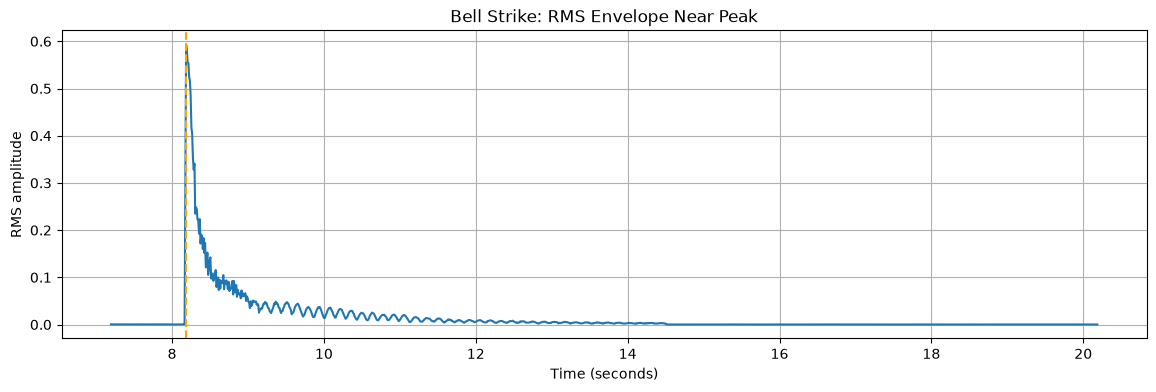

In [8]:
name = 'Bell'
peak_time = verified_peak_times[name][0]

data = rms_envelopes[name]
times = data['times']
rms = data['rms']

# Numpy arrays use the & symbol. Tricky tricky.
mask = (times >= peak_time - 1.0) & (times <= peak_time + 12.0)

plt.figure(figsize=(14, 4))
plt.plot(times[mask], rms[mask])
plt.axvline(peak_time, color='orange', linestyle='--', label='RMS peak')
plt.xlabel('Time (seconds)')
plt.ylabel('RMS amplitude')
plt.title(f'{name} Strike: RMS Envelope Near Peak')
plt.grid(True)
plt.show()

In [10]:
# Quick search for the minimum distance between peaks.
minimum_distance = float('inf')
for time in verified_peak_times.values():
    for i in range(len(time) - 1):
        if time[i+1] - time[i] < minimum_distance:
            minimum_distance = time[i+1] - time[i]
print(minimum_distance)

8.07


## Separating Strike Events

Switching between the different strike locations and examining different strikes within each location using the graph in cell 15 (RMS Envelope Near Peak), we see that the peak occurs almost instantly after the strike occurs, and is decayed to a significant point after roughly 7.5 seconds at a max. Coupling this with the minimum distance between any two peaks found in the loop directly above, the decision is now made to use an 8 second audio segement for each strike. We will use a window of 0.5 seconds before the peak and 7.5 seconds after. While grabbing 0.5 seconds before the peak doesn't ensure that the previous strike has completely decayed, it does appear to have decayed enough to make it insignificant for our purposes. 

We're using a consistent duration here to allow the frequency characteristics and temporal decay of the three strike locations to be compared under the same analysis conditions. A similar pattern to what was used in cell 6 to separate the separate strike locations will be used here to further separate each strike.

In [11]:
time_before_peak = 0.5
time_after_peak = 7.5

# Converting the time intervals into numbers of audio samples
samples_before = int(time_before_peak*sample_rate)
samples_after = int(time_after_peak*sample_rate)

# Need a place to store the segments
segments = {}

# Now to loop through each location and time further within each location.
for name, peak_times in verified_peak_times.items():
    segments[name] = []

    for peak_time in peak_times:
        peak_index = int(round(peak_time*sample_rate))
        start_index = peak_index - samples_before
        end_index = peak_index + samples_after

        segment = audio_float[start_index:end_index]
        segments[name].append(segment)

print(f'Samples per segment: {samples_before + samples_after}')
print(f'Duration per segment: {(samples_before + samples_after)/sample_rate} seconds')

for name, group_segments in segments.items():
    print(f'{name}: {len(group_segments)} segments')

Samples per segment: 384000
Duration per segment: 8.0 seconds
Bell: 20 segments
Bow: 20 segments
Edge: 20 segments
